# Laboratorio · Cuando y no es un número cualquiera (versión profesor)

**La pregunta:** ¿esta tienda va a pedir tequila la próxima semana? Y si pide, ¿cuántas botellas?

Usamos las ventas reales de licor del estado de Iowa (Iowa Liquor Sales, dominio público). Cada fila es una tienda en una semana en que compró algo al estado, y la variable a explicar es cuántas botellas pidió de un solo producto: Jose Cuervo Especial Reposado de 750 ml. Son 400 tiendas, de marzo de 2012 a agosto de 2016.

Es un problema de demanda intermitente, como el de refacciones: la mayoría de las semanas no se pide nada y cuando se pide llega una caja completa. En la segunda parte volvemos al vodka de la clase pasada para modelar participaciones de mercado.

Las variables explicativas usan solo semanas anteriores (no hay fuga), y evaluamos siempre en el último año, sin tocarlo para entrenar. Antes de cada celda marcada, escribe tu predicción.

| Columna | Qué es |
| --- | --- |
| `pidio`, `botellas` | Si la tienda pidió el tequila esa semana y cuántas botellas |
| `tam_tienda` | Log de las botellas semanales de todos los productos en las 8 semanas anteriores |
| `pedidos_ult8`, `botellas_ult8` | Semanas con pedido y botellas pedidas del tequila en las 8 semanas activas anteriores |
| `semanas_desde_ultimo` | Semanas desde el último pedido del tequila (tope 52) |
| `feriado` | Semana de Acción de Gracias, Navidad o Año Nuevo |

## Preparación

In [1]:
# Funciona igual en tu computadora y en Colab (en Colab descarga el repo la primera vez)
import os, subprocess, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/glm-clasificacion-lab"):
        subprocess.run(["git", "clone", "-q", "https://github.com/nielspac177/glm-clasificacion-lab.git", "/content/glm-clasificacion-lab"], check=True)
    os.chdir("/content/glm-clasificacion-lab/notebooks")
sys.path.append("../src")

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de cambios de nombre en scikit-learn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, recall_score, precision_score

from glm_lab import (cargar_tequila, cargar_vodka, separar_por_fecha, momios, inv_logit, umbral_por_costos,
                     costo_total, brier, tabla_calibracion, dispersion_pearson, prob_cero_poisson, prob_cero_nb,
                     cuantil_nb)

d = cargar_tequila("../data/iowa_tequila_tienda_semana.csv")
d["log_bot8"] = np.log1p(d["botellas_ult8"])          # botellas pedidas en las 8 semanas anteriores, en log
d["log_desde"] = np.log1p(d["semanas_desde_ultimo"])  # semanas desde el último pedido, en log
entrena, prueba = separar_por_fecha(d, "2015-09-01")
X = "tam_tienda + pedidos_ult8 + log_bot8 + log_desde + feriado + C(mes)"
print(f"entrenamiento: {len(entrena):,} filas · prueba (último año): {len(prueba):,} filas")
d.head()

entrenamiento: 61,748 filas · prueba (último año): 16,669 filas


,semana,tienda,condado,pidio,botellas,tam_tienda,pedidos_ult8,botellas_ult8,semanas_desde_ultimo,mes,feriado,log_bot8,log_desde
0,2012-02-27,2106,Black Hawk,0,0,7.2913,2,24,2,2,0,3.218876,1.098612
1,2012-02-27,2190,Polk,1,2,9.0996,7,23,1,2,0,3.178054,0.693147
2,2012-02-27,2191,Lee,0,0,7.0458,4,10,1,2,0,2.397895,0.693147
3,2012-02-27,2367,Page,1,12,5.7191,1,12,6,2,0,2.564949,1.945910
4,2012-02-27,2413,Dubuque,0,0,6.9014,0,0,52,2,0,0.000000,3.970292


## Nivel 0 · Mirar antes de modelar

**Predice antes de correr.** ¿Qué porcentaje de las tienda-semanas crees que tiene cero botellas? ¿Y cuál será el valor más común cuando sí hay pedido?

_Tu predicción:_ 

In [2]:
y = d["botellas"]
print(f"semanas sin pedido: {(y == 0).mean():.1%}   media: {y.mean():.2f}   varianza: {y.var():.1f}")
y[y > 0].value_counts(normalize=True).head(8).round(3)

semanas sin pedido: 82.3%   media: 1.77   varianza: 46.1


botellas
12    0.576
2     0.111
3     0.100
4     0.061
1     0.053
6     0.040
24    0.027
5     0.013
Name: proportion, dtype: float64

**Explica.** ¿Qué te dice que la varianza sea 26 veces la media? ¿Y el pico en 12?

> El 82% de las semanas no hay pedido y, cuando lo hay, el valor más común es 12 (58% de los pedidos): la tienda compra una caja. La varianza (46) es 26 veces la media (1.8). Un modelo de Poisson supone que son iguales, así que va a quedarse corto con los ceros y con los pedidos grandes. Y el pico en 12 avisa que cuánto se pide depende de cómo se empaca, no solo de la demanda.

## Nivel 1 · ¿Qué pasa si usamos la regresión de la clase pasada?

Ajustamos mínimos cuadrados a la variable 0/1 (el *modelo de probabilidad lineal*) y a las botellas.

**Predice antes de correr.** ¿Qué fracción de las predicciones de probabilidad caerá fuera de [0, 1] en el último año? ¿Y cuántas predicciones de botellas serán negativas?

_Tu predicción:_ 

In [3]:
mpl = smf.ols("pidio ~ " + X, entrena).fit()
p_mpl = mpl.predict(prueba)
mco_bot = smf.ols("botellas ~ " + X, entrena).fit()
b_mco = mco_bot.predict(prueba)
print(f"probabilidades fuera de [0, 1]: {((p_mpl < 0) | (p_mpl > 1)).mean():.1%}  (mín {p_mpl.min():.3f}, máx {p_mpl.max():.3f})")
print(f"botellas negativas: {(b_mco < 0).mean():.1%}  (mínimo {b_mco.min():.2f})")

probabilidades fuera de [0, 1]: 0.0%  (mín 0.025, máx 0.726)
botellas negativas: 6.5%  (mínimo -1.39)


**Explica.** ¿La recta falla siempre?

> Con estos datos, ninguna probabilidad sale de [0, 1]: van de 0.03 a 0.73. Cuando las probabilidades están lejos de 0 y de 1, el modelo lineal da efectos promedio razonables (Angrist y Pischke lo defienden por eso). Con los conteos sí falla: 6.5% de las predicciones son botellas negativas. El problema aparece en los extremos, que es justo donde viven los productos de baja rotación.

## Nivel 2 · Regresión logística

El modelo es lineal en los **log-momios**: log(p / (1 − p)) = a + b·x. Se estima por máxima verosimilitud.

**Ejercicio.** Ajusta la logística con la misma fórmula `X` usando `smf.logit` y guarda el resultado en `logit`.

In [4]:
logit = smf.logit("pidio ~ " + X, entrena).fit(disp=0)
logit.params.drop([c for c in logit.params.index if "mes" in c]).round(3)

Intercept      -3.728
tam_tienda      0.228
pedidos_ult8    0.443
log_bot8       -0.109
log_desde       0.046
feriado         0.229
dtype: float64

Un coeficiente de la logística se lee en log-momios. Para llevarlo a algo legible hay dos caminos: elevar e (razón de momios) o calcular el cambio en probabilidad.

In [5]:
razon = np.exp(logit.params[["tam_tienda", "pedidos_ult8", "feriado"]])
ame = logit.get_margeff().summary_frame().loc[["tam_tienda", "pedidos_ult8", "feriado"], "dy/dx"]
pd.DataFrame({"coef (log-momios)": logit.params[razon.index], "razón de momios": razon,
              "coef / 4": logit.params[razon.index] / 4, "efecto promedio en p": ame}).round(3)

,coef (log-momios),razón de momios,coef / 4,efecto promedio en p
tam_tienda,0.228,1.256,0.057,0.031
pedidos_ult8,0.443,1.557,0.111,0.061
feriado,0.229,1.257,0.057,0.031


**Explica.** Una semana más con pedido en las últimas 8: ¿cuánto cambia la probabilidad de pedir?

> Multiplica los momios por 1.56 (56% más). En probabilidad, el efecto promedio es de 6.1 puntos. La regla de dividir el coeficiente entre 4 (Gelman, Hill y Vehtari) da 11 puntos: es el efecto máximo, el que se tiene cuando p = 0.5. Aquí la tasa típica ronda 0.18, así que el efecto real es la mitad. El mismo coeficiente mueve poco la probabilidad cerca de 0 y mucho cerca de 0.5.

## Nivel 3 · Lo que scikit-learn hace sin avisar

`LogisticRegression()` de scikit-learn **penaliza por defecto** (Ridge con `C=1`). Tomamos una muestra chica de 200 filas.

**Predice antes de correr.** Con 200 filas, ¿se parecerán mucho los coeficientes con y sin penalización?

_Tu predicción:_ 

In [6]:
cols = ["tam_tienda", "pedidos_ult8", "log_bot8", "log_desde", "feriado"]
muestra = entrena.sample(200, random_state=86)
por_defecto = LogisticRegression(max_iter=5000).fit(muestra[cols], muestra["pidio"]).coef_[0]
sin_penalizar = LogisticRegression(penalty=None, max_iter=5000).fit(muestra[cols], muestra["pidio"]).coef_[0]
print(pd.DataFrame({"C=1 (por defecto)": por_defecto, "sin penalizar": sin_penalizar}, index=cols).round(2))
pd.crosstab(muestra["feriado"], muestra["pidio"])

              C=1 (por defecto)  sin penalizar
tam_tienda                 0.14           0.17
pedidos_ult8               0.55           0.59
log_bot8                  -0.08          -0.08
log_desde                  0.29           0.33
feriado                   -0.78          -9.74


pidio,0,1
feriado,,
0,159,33
1,8,0


**Explica.** ¿Qué pasó con `feriado`?

> Mira la tabla cruzada: en las 8 semanas de feriado de la muestra ninguna tienda pidió, así que el modelo puede predecir 'no pide' con certeza en feriado. La verosimilitud sigue subiendo mientras el coeficiente se va a menos infinito y no existe un máximo finito: es la separación (Albert y Anderson, 1984). Sin penalizar, el coeficiente llega a −9.7, que en momios es dividir entre 17 mil; con la penalización por defecto queda en −0.78 y nada te avisa. Con todos los datos, el coeficiente real es +0.23: en feriado se pide un poco más. Para interpretar coeficientes usa statsmodels o `penalty=None`; para muestras chicas o eventos raros, la corrección de Firth (1993) es la salida estándar.

## Nivel 4 · LDA: la otra forma de clasificar

La logística modela directamente P(pide | x). El análisis discriminante lineal (LDA) modela cómo se distribuye x **dentro** de cada clase (normal, con la misma covarianza) y luego usa Bayes para obtener P(pide | x). La frontera también es lineal.

**Ejercicio.** Ajusta `LinearDiscriminantAnalysis()` con las columnas `cols` y calcula su AUC en prueba, igual que la logística.

In [7]:
modelos = {"logística": LogisticRegression(penalty=None, max_iter=5000), "LDA": LinearDiscriminantAnalysis(),
           "QDA": QuadraticDiscriminantAnalysis()}
for nombre, m in modelos.items():
    q = m.fit(entrena[cols], entrena["pidio"]).predict_proba(prueba[cols])[:, 1]
    print(f"{nombre:10s} AUC {roc_auc_score(prueba['pidio'], q):.3f}   log-loss {log_loss(prueba['pidio'], q):.4f}")

logística  AUC 0.659   log-loss 0.4328
LDA        AUC 0.658   log-loss 0.4347
QDA        AUC 0.683   log-loss 0.4953


Con 60 mil filas, la logística y LDA quedan prácticamente empatadas. QDA ordena mejor a las tiendas (AUC más alto) pero sus probabilidades son peores (log-loss más alto): ordenar bien y dar probabilidades creíbles son dos cosas distintas. ¿Y con pocos datos? Repetimos 200 veces el ajuste con muestras chicas y medimos el log-loss en el último año (más bajo es mejor).

**Predice antes de correr.** Con 30 o 60 filas de entrenamiento, ¿cuál crees que gana: LDA o la logística?

_Tu predicción:_ 

In [8]:
rng = np.random.default_rng(0)
filas = []
for n in [30, 60, 120, 250, 1000]:
    for k in range(200):
        m = entrena.iloc[rng.choice(len(entrena), n, replace=False)]
        if m["pidio"].sum() < 2:
            continue
        for nombre, mod in [("logística", LogisticRegression(penalty=None, max_iter=5000)), ("LDA", LinearDiscriminantAnalysis())]:
            q = np.clip(mod.fit(m[cols], m["pidio"]).predict_proba(prueba[cols])[:, 1], 1e-6, 1 - 1e-6)
            filas.append({"n": n, "modelo": nombre, "log_loss": log_loss(prueba["pidio"], q)})
pd.DataFrame(filas).pivot_table(index="n", columns="modelo", values="log_loss", aggfunc="median").round(3)

modelo,LDA,logística
n,,
30,0.574,0.619
60,0.488,0.536
120,0.461,0.470
250,0.447,0.445
1000,0.437,0.436


**Explica.** ¿Por qué LDA gana con pocos datos y empata con muchos?

> LDA usa más supuestos: que x es normal dentro de cada clase con la misma covarianza. Si los supuestos son más o menos razonables, esa información extra le ahorra datos: con 30 filas su log-loss es 0.57 contra 0.62 de la logística. Con 250 filas o más quedan iguales, y con muchos datos la logística gana por poco porque no depende de supuestos que aquí no se cumplen (feriado es 0/1, no normal). Es el resultado de Efron (1975) y de Ng y Jordan (2001): el modelo generativo llega antes a su error límite y el discriminativo tiene un límite más bajo.

## Nivel 5 · ¿Qué tan bueno es el clasificador?

**Predice antes de correr.** Un modelo que dice siempre 'no pide', ¿qué exactitud tendrá en el último año? ¿Y la logística con umbral 0.5?

_Tu predicción:_ 

In [9]:
y_te = prueba["pidio"].to_numpy()
p_log = logit.predict(prueba).to_numpy()
print(f"exactitud de 'nunca pide': {1 - y_te.mean():.1%}")
print(f"logística con umbral 0.5: exactitud {np.mean((p_log >= 0.5) == y_te):.1%}, recall {recall_score(y_te, p_log >= 0.5):.1%}")
print(f"AUC ROC {roc_auc_score(y_te, p_log):.3f}   precisión promedio (área PR) {average_precision_score(y_te, p_log):.3f}"
      f"   tasa de positivos {y_te.mean():.3f}")

exactitud de 'nunca pide': 83.1%
logística con umbral 0.5: exactitud 83.0%, recall 3.8%
AUC ROC 0.656   precisión promedio (área PR) 0.288   tasa de positivos 0.169


**Explica.** ¿Por qué la exactitud no sirve aquí y qué miramos en su lugar?

> Decir siempre que no da 83.1% de exactitud, y la logística con umbral 0.5 da 83.0% con un recall de 4%: casi nunca se anima a decir 'sí'. Con eventos raros la exactitud premia ignorar la clase que importa. El AUC (0.66) mide si ordena bien a las tiendas; la precisión promedio (0.29) se compara contra la tasa de positivos (0.17), que es lo que daría un modelo al azar. Saito y Rehmsmeier (2015) recomiendan la curva PR justo para este caso.

**¿Las probabilidades son creíbles?** Una tabla de calibración agrupa semanas con probabilidad parecida y compara con lo que pasó.

Brier del modelo 0.1340   Brier de predecir la tasa 0.1408


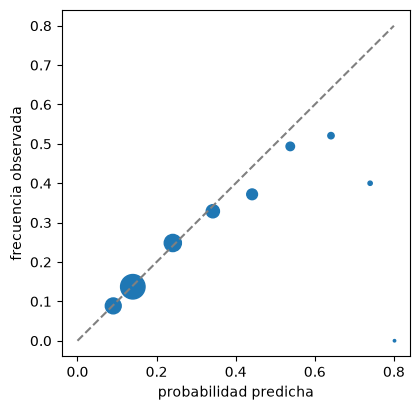

,grupo,n,p_media,frecuencia
0,"[0.0, 0.1)",1898,0.090,0.089
1,"[0.1, 0.2)",10676,0.140,0.137
2,"[0.2, 0.3)",2582,0.241,0.248
3,"[0.3, 0.4)",900,0.342,0.329
4,"[0.4, 0.5)",398,0.442,0.372
5,"[0.5, 0.6)",156,0.538,0.494
6,"[0.6, 0.7)",48,0.641,0.521
7,"[0.7, 0.8)",10,0.740,0.400
8,"[0.8, 0.9)",1,0.802,0.000


In [10]:
cal = tabla_calibracion(y_te, p_log, n_grupos=10)
print(f"Brier del modelo {brier(y_te, p_log):.4f}   Brier de predecir la tasa {brier(y_te, np.full_like(p_log, entrena['pidio'].mean())):.4f}")
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 0.8], [0, 0.8], "--", color="gray")
ax.scatter(cal["p_media"], cal["frecuencia"], s=np.sqrt(cal["n"]) * 3)
ax.set_xlabel("probabilidad predicha"); ax.set_ylabel("frecuencia observada")
plt.show()
cal.round(3)

**Del modelo a la decisión.** Supón que mandar al vendedor a una tienda que no iba a pedir cuesta 1 y no ir a una que sí iba a pedir cuesta 5. Con probabilidades calibradas, el umbral que minimiza el costo es costo_FP / (costo_FP + costo_FN) (Elkan, 2001).

**Ejercicio.** Calcula el umbral con `umbral_por_costos` y compara el costo total contra el umbral 0.5 con `costo_total`.

In [11]:
u = umbral_por_costos(costo_fp=1, costo_fn=5)
for umbral in [0.5, u]:
    print(f"umbral {umbral:.3f}: costo {costo_total(y_te, p_log, umbral, 1, 5):,}   "
          f"recall {recall_score(y_te, p_log >= umbral):.0%}   precisión {precision_score(y_te, p_log >= umbral):.0%}")
print(f"nunca ir: {costo_total(y_te, np.zeros_like(p_log), 0.5, 1, 5):,}")

umbral 0.500: costo 13,694   recall 4%   precisión 49%
umbral 0.167: costo 10,799   recall 56%   precisión 26%
nunca ir: 14,115


**Explica.** ¿Por qué el umbral no es 0.5?

> Con un FN que cuesta 5 veces un FP, conviene decir 'sí' desde una probabilidad de 1/6. El costo baja 21% (de 13,694 a 10,799) y el recall sube de 4% a 56%. El 0.5 solo es el umbral correcto cuando los dos errores cuestan lo mismo. Y la regla depende de que las probabilidades estén calibradas: por eso se revisa la calibración antes de fijar umbrales.

## Nivel 6 · Contar botellas: Poisson y binomial negativa

La regresión de Poisson usa enlace log: log E[y] = a + b·x. Un coeficiente se lee como razón de tasas: e^b es por cuánto se multiplica la media.

**Predice antes de correr.** La Poisson ajustada, ¿qué porcentaje de semanas sin pedido predecirá en el último año? (Observado: 83%)

_Tu predicción:_ 

In [12]:
poisson = smf.glm("botellas ~ " + X, entrena, family=sm.families.Poisson()).fit()
mu_p = poisson.predict(prueba)
print(f"dispersión de Pearson: {dispersion_pearson(entrena['botellas'], poisson.fittedvalues, len(poisson.params)):.1f}  (Poisson supone 1)")
print(f"ceros: observados {(prueba['botellas'] == 0).mean():.1%}   Poisson predice {prob_cero_poisson(mu_p).mean():.1%}")

dispersión de Pearson: 24.4  (Poisson supone 1)
ceros: observados 83.1%   Poisson predice 27.1%


**Ejercicio.** Ajusta la binomial negativa con `smf.negativebinomial` y la misma fórmula; guarda `alpha` y la media predicha `mu_nb`.

In [13]:
bn = smf.negativebinomial("botellas ~ " + X, entrena).fit(disp=0, maxiter=200)
alpha, mu_nb = bn.params["alpha"], bn.predict(prueba)
print(f"alpha = {alpha:.1f}   ceros predichos {prob_cero_nb(mu_nb, alpha).mean():.1%}   AIC Poisson {poisson.aic:,.0f}   AIC BN {bn.aic:,.0f}")

alpha = 15.2   ceros predichos 81.5%   AIC Poisson 456,346   AIC BN 133,959


In [14]:
robusta = smf.glm("botellas ~ " + X, entrena, family=sm.families.Poisson()).fit(cov_type="HC1")
pd.DataFrame({"razón de tasas": np.exp(poisson.params[["pedidos_ult8", "feriado"]]),
              "EE Poisson": poisson.bse[["pedidos_ult8", "feriado"]],
              "EE Poisson robusto": robusta.bse[["pedidos_ult8", "feriado"]],
              "EE binomial negativa": bn.bse[["pedidos_ult8", "feriado"]]}).round(4)

,razón de tasas,EE Poisson,EE Poisson robusto,EE binomial negativa
pedidos_ult8,1.1162,0.0029,0.0133,0.0199
feriado,1.2933,0.0183,0.0739,0.1009


**Explica.** ¿Qué estaba mal con la Poisson y qué no?

> La dispersión es 24: la varianza es mucho mayor que la media. Por eso la Poisson predice 27% de semanas sin pedido cuando hubo 83%, y su error estándar es 4 a 7 veces más chico que el robusto o el de la binomial negativa. Lo que sí está bien es la media: los coeficientes de Poisson son consistentes aunque la varianza esté mal, siempre que se reporten errores robustos (Ver Hoef y Boveng, 2007, comparan esta salida con la binomial negativa). Si solo te importa la media, Poisson con errores robustos alcanza. Si te importa la distribución completa, como para un inventario, necesitas la binomial negativa.

## Nivel 7 · Dos preguntas separadas: ¿pide? y ¿cuánto?

Un modelo *hurdle* (Mullahy, 1986) multiplica dos modelos: la probabilidad de pedir (la logística del nivel 2) y el tamaño del pedido cuando sí hay pedido. Es la misma idea de Croston (1972) para demanda intermitente.

In [15]:
con_pedido = entrena[entrena["botellas"] > 0]
tamano = smf.glm("botellas ~ " + X, con_pedido, family=sm.families.Poisson()).fit()
hurdle = p_log * tamano.predict(prueba)
yb = prueba["botellas"].to_numpy()
pronosticos = {"cero siempre": np.zeros_like(yb, dtype=float), "promedio 8 semanas": prueba["botellas_ult8"] / 8,
               "MCO": b_mco, "Poisson": mu_p, "binomial negativa": mu_nb, "hurdle": hurdle}
pd.DataFrame({n: {"MAE": np.mean(np.abs(yb - f)), "RMSE": np.sqrt(np.mean((yb - f) ** 2))}
              for n, f in pronosticos.items()}).T.round(3)

,MAE,RMSE
cero siempre,1.641,6.570
promedio 8 semanas,2.618,6.555
MCO,2.702,6.271
Poisson,2.659,6.246
binomial negativa,2.689,6.265
hurdle,2.666,6.248


**Explica.** ¿Por qué 'cero siempre' tiene el mejor MAE? ¿Significa que es el mejor pronóstico?

> El MAE se minimiza con la mediana, y la mediana de una demanda con 83% de ceros es cero. Así que el pronóstico que nunca pide nada gana en MAE (1.64 contra 2.6 de los modelos) y es inútil para reponer inventario. Kolassa (2016) muestra este problema con ventas de retail. Para demanda intermitente se evalúa la distribución completa, o al menos el error cuadrático y la cobertura de los cuantiles, que es lo que hacemos en el siguiente nivel.

## Nivel 8 · De la distribución a un máximo de inventario

Un máximo con nivel de servicio de 95% es el cuantil 0.95 de la demanda de la semana. Lo calculamos con tres supuestos y medimos la **cobertura**: en qué fracción de semanas del último año la demanda quedó por debajo del máximo.

**Predice antes de correr.** ¿Cuál crees que se acerca más al 95% prometido: la normal (regresión lineal), la Poisson o la binomial negativa?

_Tu predicción:_ 

In [16]:
filas = []
for q in [0.90, 0.95]:
    maximos = {"normal (MCO)": b_mco + stats.norm.ppf(q) * np.sqrt(mco_bot.scale),
               "Poisson": stats.poisson(mu_p).ppf(q),
               "binomial negativa": cuantil_nb(mu_nb, alpha, q)}
    for nombre, m in maximos.items():
        filas.append({"nivel": q, "supuesto": nombre, "cobertura": np.mean(yb <= m), "máximo promedio": np.mean(m)})
pd.DataFrame(filas).round(3)

,nivel,supuesto,cobertura,máximo promedio
0,0.90,normal (MCO),0.927,10.442
1,0.90,Poisson,0.872,3.395
2,0.90,binomial negativa,0.874,3.635
3,0.95,normal (MCO),0.986,12.910
4,0.95,Poisson,0.880,3.992
5,0.95,binomial negativa,0.949,10.227


**Explica.** ¿Qué supuesto usarías para fijar un máximo y por qué?

> La binomial negativa promete 95% y cumple 94.9%, con un máximo promedio de 10 botellas. La normal cubre de más (98.6%) con casi 13 botellas: inventario de sobra en cada tienda. La Poisson se queda en 88% con 4 botellas: faltantes. El supuesto sobre la varianza decide el inventario aunque las tres tengan casi la misma media.

## Nivel 9 · Participaciones de mercado: un número entre 0 y 1

Volvemos al vodka de la clase pasada. La participación (`share`) de cada proveedor vive entre 0 y 1. El *logit fraccional* (Papke y Wooldridge, 1996) usa la verosimilitud binomial con enlace logit sobre la proporción, con errores robustos.

In [17]:
v = cargar_vodka("../data/iowa_vodka_semanal.csv")
v["log_precio"] = np.log(v["precio_litro"])
mco_share = smf.ols("share ~ log_precio + C(proveedor)", v).fit()
frac = smf.glm("share ~ log_precio + C(proveedor)", v, family=sm.families.Binomial()).fit(cov_type="HC1")
print(f"MCO: {mco_share.params['log_precio']:.3f} puntos de share por unidad de log precio")
print(f"logit fraccional: {frac.params['log_precio']:.2f} en log-momios (EE robusto {frac.bse['log_precio']:.2f})")

MCO: -0.161 puntos de share por unidad de log precio
logit fraccional: -1.73 en log-momios (EE robusto 0.21)


**Predice antes de correr.** Si cada proveedor sube 50% su precio, ¿alguno tendrá share negativo según MCO?

_Tu predicción:_ 

In [18]:
filas = []
for prov, g in v.groupby("proveedor"):
    g = g.assign(log_precio=g["log_precio"] + np.log(1.5))
    filas.append({"proveedor": prov, "share actual": v.loc[v["proveedor"] == prov, "share"].mean(),
                  "MCO": mco_share.predict(g).mean(), "semanas negativas (MCO)": (mco_share.predict(g) < 0).mean(),
                  "logit fraccional": frac.predict(g).mean()})
pd.DataFrame(filas).round(3)

,proveedor,share actual,MCO,semanas negativas (MCO),logit fraccional
0,DIAGEO AMERICAS,0.141,0.076,0.000,0.075
1,LAIRD AND COMPANY,0.099,0.034,0.000,0.052
2,LUXCO-ST LOUIS,0.174,0.109,0.000,0.095
3,MCCORMICK DISTILLING COMPANY,0.063,-0.003,0.914,0.032
4,PERNOD RICARD USA/AUSTIN NICHOLS,0.067,0.002,0.469,0.034
5,PHILLIPS BEVERAGE COMPANY,0.138,0.073,0.000,0.074
6,"SAZERAC CO., INC.",0.032,-0.034,1.000,0.016
7,SAZERAC NORTH AMERICA,0.110,0.045,0.000,0.058


**Explica.** ¿Qué ganas con el logit fraccional en tu proyecto de share?

> Con MCO, SAZERAC CO. y McCormick quedan con share negativo en casi todas las semanas: el efecto del precio es el mismo número de puntos para todos, y a un proveedor chico se le acaba el share. En el logit fraccional el efecto es proporcional a share × (1 − share), así que un proveedor con 3% pierde menos puntos que uno con 17%, y nunca sale de [0, 1]. Cerca del 50% las dos lecturas se parecen; en los extremos, que es donde están los proveedores chicos, no.

## Para tu proyecto

1. ¿Tu y es continua, 0/1, conteo o proporción? ¿Qué distribución y qué enlace le corresponden?
2. Si es un clasificador, ¿cuánto cuesta cada tipo de error? ¿De ahí sale tu umbral?
3. ¿Tus probabilidades están calibradas en el rango donde vas a decidir?
4. Si son conteos, ¿la varianza es mucho mayor que la media? ¿Hay más ceros de los que predice tu modelo?
5. ¿Evalúas la distribución o solo un promedio? ¿Con qué métrica?